# Module 03: The Pseudoreplication Delusion
**Treating 100 leaves from 4 plants as n = 100 instead of n = 2 experimental units per group** · *~5 min*

*Created by [Lungh](https://github.com/lunganlungpg) · part of [Experimental Design Gone Wrong](https://github.com/lunganlungpg/experimental-design-gone-wrong)*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lunganlungpg/experimental-design-gone-wrong/blob/main/03_pseudoreplication_delusion/03_pseudoreplication_delusion.ipynb)


## 1. The Setup (The Blunder)

Low on bench space, a plant physiologist grows only **2 plants under Control** and **2 plants under Fertilizer** ($n = 2$ biological experimental units per group), then eagerly plucks 25 leaves from every plant (`100` leaves total; 50 per treatment). *(Side note: if they had used just 1 plant per arm—50 leaves from 2 plants total—they'd have 0 residual degrees of freedom and not even a mixed model could save them!)* Instead of modeling plant-to-plant variation, they dump all 100 leaf measurements straight into a naive `ttest_ind` pretending every leaf is an independent plant, and panic when it claims Fertilizer *shrank* leaf area by 2.64 cm² (`p < 1e-6`).

In [1]:
# Works locally out of the box; in Google Colab, clones the repo for src/.
import subprocess
import sys
from pathlib import Path

GITHUB_REPO = "lunganlungpg/experimental-design-gone-wrong"

for root in (Path.cwd(), Path.cwd().parent):
    if (root / "src" / "simulate_blunders.py").exists():
        if str(root) not in sys.path:
            sys.path.insert(0, str(root))
        break
else:
    clone_dir = Path("/content/experimental-design-gone-wrong")
    if not clone_dir.exists():
        subprocess.run(
            ["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(clone_dir)],
            check=True,
        )
    sys.path.insert(0, str(clone_dir))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

from src.simulate_blunders import (
    PALETTE,
    build_comparison_table,
    format_p_value,
    set_publication_style,
    simulate_pseudoreplication,
)

set_publication_style()
df = simulate_pseudoreplication(seed=2)
print(f"Total rows (leaves): {len(df)} | Actual plants: {df['plant_id'].nunique()}")
df.head(6)

Total rows (leaves): 100 | Actual plants: 4


,obs_id,plant_id,treatment,leaf_num,leaf_area_cm2
0,1,Control_Plant_1,Control,1,24.78
1,2,Control_Plant_1,Control,2,24.95
2,3,Control_Plant_1,Control,3,21.90
3,4,Control_Plant_1,Control,4,28.27
4,5,Control_Plant_1,Control,5,27.28
5,6,Control_Plant_1,Control,6,25.08


## 2. The Crime (Naive Analysis)

Here is the classic Hurlbert (1984) pseudoreplication felony: pretending 25 leaves plucked off the exact same root system are 25 independent biological replicates (`df = 98`).

In [2]:
naive_ols = smf.ols("leaf_area_cm2 ~ C(treatment)", data=df).fit()
naive_est = naive_ols.params["C(treatment)[T.Fertilized]"]
naive_ci = naive_ols.conf_int().loc["C(treatment)[T.Fertilized]"].tolist()
naive_p = float(naive_ols.pvalues["C(treatment)[T.Fertilized]"])

print(f"Naive OLS / t-test (df = {int(naive_ols.df_resid)}):")
print(f"  Effect = {naive_est:+.2f} cm^2, 95% CI = [{naive_ci[0]:+.2f}, {naive_ci[1]:+.2f}], p = {format_p_value(naive_p)}")
print("  --> Wildly overconfident because 100 leaves != 100 independent plants!")

Naive OLS / t-test (df = 98):
  Effect = -2.64 cm^2, 95% CI = [-3.60, -1.68], p = 3.73e-07
  --> Wildly overconfident because 100 leaves != 100 independent plants!


## 3. The Reality Check (Visual Punchline)

Left: plotting all 100 leaves grouped by `plant_id` exposes the giant secret—leaves within each plant cluster tightly around that plant's own random baseline, while plants differ dramatically from one another. Right: watch how the naive 95% CI shrinks to a tiny mirage compared to honest plant-level uncertainty.

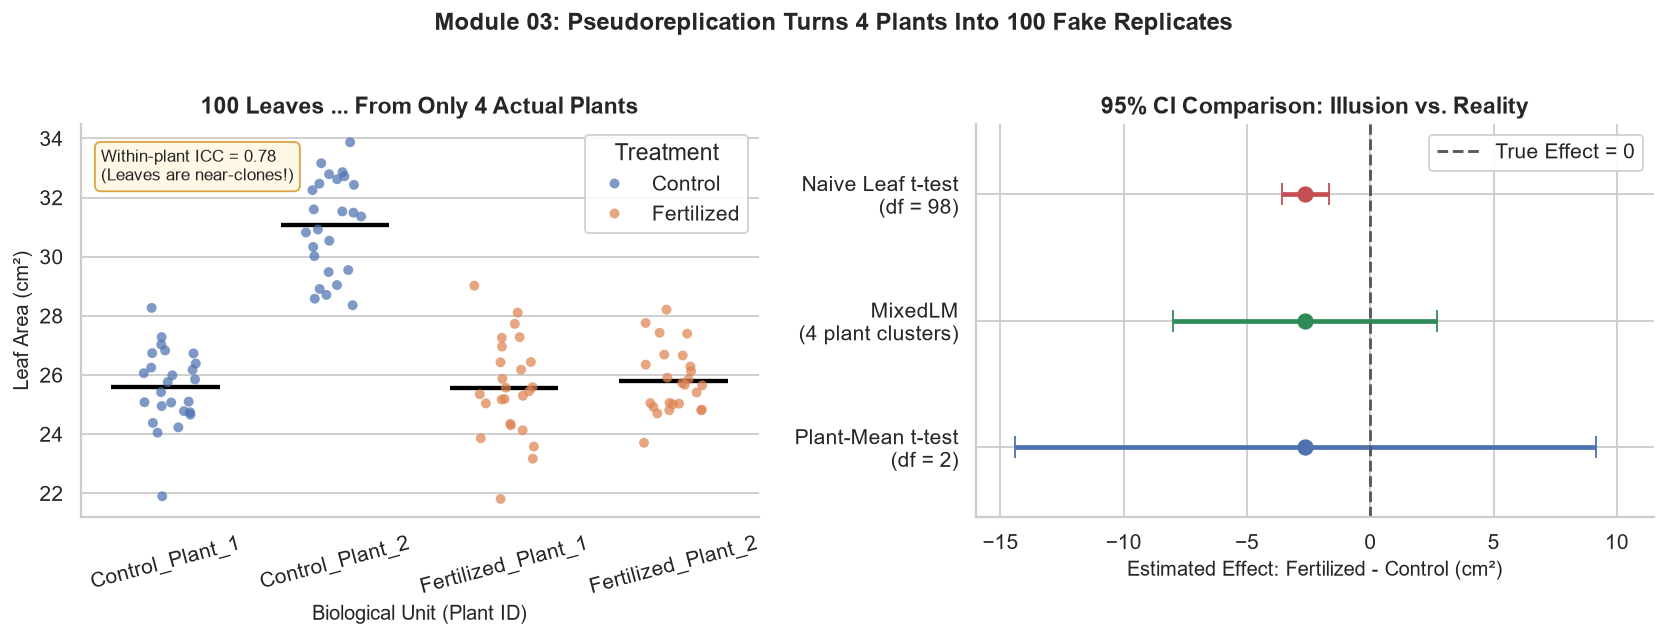

In [3]:
# Fit proper models first so Panel B can compare intervals directly
mlm = smf.mixedlm("leaf_area_cm2 ~ C(treatment)", data=df, groups=df["plant_id"]).fit(reml=True)
plant_means = df.groupby(["plant_id", "treatment"], as_index=False, observed=True)["leaf_area_cm2"].mean()
unit_ols = smf.ols("leaf_area_cm2 ~ C(treatment)", data=plant_means).fit()

# Compute intraclass correlation (ICC) from variance components
var_plant = float(mlm.cov_re.iloc[0, 0])
var_leaf = float(mlm.scale)
icc = var_plant / (var_plant + var_leaf)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))
palette_map = {"Control": PALETTE["control"], "Fertilized": PALETTE["treated"]}

# Panel A: Clustered Leaf Measurements per Plant
sns.stripplot(
    data=df, x="plant_id", y="leaf_area_cm2", hue="treatment",
    palette=palette_map, alpha=0.72, jitter=0.18, size=5.5, ax=axes[0]
)
plant_order = ["Control_Plant_1", "Control_Plant_2", "Fertilized_Plant_1", "Fertilized_Plant_2"]
for idx, pid in enumerate(plant_order):
    m_val = plant_means.loc[plant_means["plant_id"] == pid, "leaf_area_cm2"].iloc[0]
    axes[0].hlines(m_val, idx - 0.32, idx + 0.32, color="black", lw=2.4)
axes[0].text(
    0.03, 0.94, f"Within-plant ICC = {icc:.2f}\n(Leaves are near-clones!)",
    transform=axes[0].transAxes, va="top", fontsize=9.5,
    bbox={"boxstyle": "round,pad=0.35", "facecolor": "#FFF8E7", "edgecolor": "#D9A441"}
)
axes[0].set_title("100 Leaves ... From Only 4 Actual Plants")
axes[0].set_xlabel("Biological Unit (Plant ID)")
axes[0].set_ylabel("Leaf Area (cm²)")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(title="Treatment", loc="upper right")

# Panel B: Fake vs True Confidence Intervals
mlm_est = float(mlm.fe_params["C(treatment)[T.Fertilized]"])
mlm_ci = mlm.conf_int().loc["C(treatment)[T.Fertilized]"].tolist()
unit_est = float(unit_ols.params["C(treatment)[T.Fertilized]"])
unit_ci = unit_ols.conf_int().loc["C(treatment)[T.Fertilized]"].tolist()

labels = ["Naive Leaf t-test\n(df = 98)", "MixedLM\n(4 plant clusters)", "Plant-Mean t-test\n(df = 2)"]
ests = [naive_est, mlm_est, unit_est]
lows = [naive_ci[0], mlm_ci[0], unit_ci[0]]
highs = [naive_ci[1], mlm_ci[1], unit_ci[1]]
colors = [PALETTE["danger"], PALETTE["safe"], PALETTE["control"]]

y_pos = np.arange(len(labels))
for i in range(len(labels)):
    axes[1].errorbar(
        ests[i], y_pos[i],
        xerr=[[ests[i] - lows[i]], [highs[i] - ests[i]]],
        fmt="o", color=colors[i], ecolor=colors[i], elinewidth=2.6, capsize=6, ms=8
    )
axes[1].axvline(0.0, color=PALETTE["neutral"], ls="--", lw=1.6, label="True Effect = 0")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(labels)
axes[1].set_ylim(-0.55, 2.55)
axes[1].set_xlim(-16.0, 11.5)
axes[1].invert_yaxis()
axes[1].set_title("95% CI Comparison: Illusion vs. Reality")
axes[1].set_xlabel("Estimated Effect: Fertilized - Control (cm²)")
axes[1].legend(loc="upper right")

fig.suptitle("Module 03: Pseudoreplication Turns 4 Plants Into 100 Fake Replicates", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 4. The Fix (Proper Model)

We fit two proper hierarchical/unit-level alternatives: (1) a **Linear Mixed-Effects Model (`MixedLM`)** with a random intercept per `plant_id`, and (2) an **exact Plant-Mean *t*-test (`df = 2`)** summarizing each biological unit to a single mean before testing. Notice that with only 4 plants, the exact `df = 2` *t*-interval is even more conservative than `MixedLM`'s asymptotic *z*-interval—and *both* clearly expose that there is zero evidence of a treatment effect.

In [4]:
mlm_p = float(mlm.pvalues["C(treatment)[T.Fertilized]"])
unit_p = float(unit_ols.pvalues["C(treatment)[T.Fertilized]"])

summary = build_comparison_table(
    [
        {
            "Model": "Naive Leaf-Level t-test / OLS",
            "Assumed Unit": "100 independent leaves",
            "df_resid": int(naive_ols.df_resid),
            "Estimate": f"{naive_est:+.2f} cm²",
            "95% CI": f"[{naive_ci[0]:+.2f}, {naive_ci[1]:+.2f}]",
            "p_value": format_p_value(naive_p),
            "Verdict": "Fake shrinkage (p < 0.0001)",
        },
        {
            "Model": "Proper MixedLM (1 | plant_id)",
            "Assumed Unit": "4 plant clusters (REML)",
            "df_resid": "4 clusters",
            "Estimate": f"{mlm_est:+.2f} cm²",
            "95% CI": f"[{mlm_ci[0]:+.2f}, {mlm_ci[1]:+.2f}]",
            "p_value": format_p_value(mlm_p),
            "Verdict": "Truth recovered (no effect)",
        },
        {
            "Model": "Exact Plant-Mean t-test",
            "Assumed Unit": "4 plants (2 per group)",
            "df_resid": int(unit_ols.df_resid),
            "Estimate": f"{unit_est:+.2f} cm²",
            "95% CI": f"[{unit_ci[0]:+.2f}, {unit_ci[1]:+.2f}]",
            "p_value": format_p_value(unit_p),
            "Verdict": "Truth recovered (exact df=2)",
        },
    ]
)
summary

,Model,Assumed Unit,df_resid,Estimate,95% CI,p_value,Verdict
0,Naive Leaf-Level t-test / OLS,100 independent leaves,98,-2.64 cm²,"[-3.60, -1.68]",3.73e-07,Fake shrinkage (p < 0.0001)
1,Proper MixedLM (1 | plant_id),4 plant clusters (REML),4 clusters,-2.64 cm²,"[-8.00, +2.72]",0.3348,Truth recovered (no effect)
2,Exact Plant-Mean t-test,4 plants (2 per group),2,-2.64 cm²,"[-14.41, +9.14]",0.4367,Truth recovered (exact df=2)


> **Rule of Thumb:** Your sample size $N$ is the number of independently randomized **experimental units** (plants, cages, classrooms), never the number of subsamples (leaves, cells, quizzes) plucked from inside them. Always average subsamples per unit or include a random cluster intercept—and remember that adding more leaves per plant never compensates for having too few plants.